# 08. Visualization

Figures for the report, organized by research question. Every value is read from the result tables written by `05` and `07` (`results/tables/*.csv`); nothing is typed in by hand. Re-run this notebook after `07` to update all figures.

1. Setup
2. Overview
   - 2.1 Results at a Glance
   - 2.2 Language Tagging Validation
3. RQ1: Generational Differences
   - 3.1 Medians by Generation
   - 3.2 Share of Songs with English
   - 3.3 Pairwise Effect Sizes
   - 3.4 Controlling for Release Period: Kruskal–Wallis
   - 3.5 Controlling for Release Period: Regression
   - 3.6 Robustness
4. RQ2: Temporal Trends
   - 4.1 Yearly Means and Trend
   - 4.2 Period Medians
   - 4.3 Period Effect Sizes
   - 4.4 Components of the Change in Lexical Diversity
   - 4.5 Most Frequent English Words
   - 4.6 Robustness

### Output
`results/figures/figNN_*.png` (300 dpi) and `.pdf` (vector) for each figure.

## 1. Setup

### Design rules
- **Generations and periods are ordered**, so they use one blue ramp from light (earliest) to dark (latest), never unrelated hues.
- **Two compared series** (e.g. all songs vs. 2015–2023) use the first two categorical colors, blue and orange, always with a legend.
- **Signed effect sizes** (Cliff's δ) use a blue–red diverging scale with a gray midpoint at 0.
- **Significance** is shown by filled vs. hollow markers or by `*` in labels, never by color alone.
- One y-axis per panel; features with different scales go in separate panels.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

TABLE_DIR = Path("../results/tables")
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load every result table
REQUIRED = [
    "summary", "language_tagging_validation", "romanized_by_period",
    "descriptives_by_generation", "rq1_kruskal_all", "rq1_kruskal_within_2015_2023", "rq1_dunn_all",
    "rq1_median_ci", "rq1_regression", "rq1_regression_time_controls", "robustness_rq1",
    "rq2_yearly_mean", "rq2_trend", "rq2_period_kruskal", "rq2_period_kruskal_korean", "rq2_period_pairs",
    "rq2_lexdiv_components", "rq2_top_english_words", "robustness_rq2",
]
missing = [n for n in REQUIRED if not (TABLE_DIR / f"{n}.csv").exists()]
assert not missing, f"Missing tables (re-run 05 and 07): {missing}"
T = {n: pd.read_csv(TABLE_DIR / f"{n}.csv", encoding="utf-8-sig") for n in REQUIRED}
print(f"Loaded {len(T)} tables from {TABLE_DIR}")

Loaded 19 tables from ../results/tables


In [2]:
# Features, labels, and order (same as 07)
MAIN_FEATURES = ["en_ratio", "phrase_len_mean", "mtld", "ttr", "cs_per100", "cs_inter_per100"]
LABELS = {
    "en_ratio": "English ratio",
    "phrase_len_mean": "Mean phrase length (tokens)",
    "mtld": "MTLD",
    "ttr": "TTR",
    "cs_per100": "Switches within lines / 100 tokens",
    "cs_inter_per100": "Switches at line breaks / 100 tokens",
}
SHORT = {"en_ratio": "English ratio", "phrase_len_mean": "Phrase length", "mtld": "MTLD", "ttr": "TTR",
         "cs_per100": "Switches within lines", "cs_inter_per100": "Switches at line breaks"}
GENS = ["1st", "2nd", "3rd", "4th"]
PERIODS = ["2000–04", "2005–09", "2010–14", "2015–19", "2020–23"]

# Palette
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
GEN_COLORS = dict(zip(GENS, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))
PERIOD_COLORS = dict(zip(PERIODS, ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]))
SEQ = mcolors.LinearSegmentedColormap.from_list("seq", ["#f7f9fd", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
DIV = mcolors.LinearSegmentedColormap.from_list("div", ["#b8312f", RED, NEUTRAL, BLUE, "#104281"])
SIG_FILL, NS_FILL = "#cde2fb", NEUTRAL
COND_LABELS = {"baseline": "Baseline", "alt_A": "Boundaries\nA", "alt_B": "Boundaries\nB", "alt_C": "Boundaries\nC",
               "nofill": "No fillers", "romko": "Romanized\n→ Korean", "high_conf": "High-conf.\ndebut years",
               "min_en_30": "≥30 English\ntokens", "min_en_100": "≥100 English\ntokens", "korean_only": "Korean\nartists only"}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif", "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 9.5, "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 7,
})


def stars(p):
    return "*" if pd.notna(p) and p < .05 else ""


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {name}.png / .pdf")


def text_on(rgba):
    # Dark ink on light cells, white on dark cells
    r, g, b = mcolors.to_rgb(rgba)
    return INK if (0.2126 * r + 0.7152 * g + 0.0722 * b) > 0.5 else "white"


def annotated_grid(ax, values, labels, cmap, norm, xticklabels, yticklabels, fills=None):
    # Heatmap-style grid with text in each cell; fills (optional) overrides colors with explicit hex
    n_r, n_c = values.shape
    for i in range(n_r):
        for j in range(n_c):
            v = values[i, j]
            if fills is not None:
                color = fills[i][j]
            else:
                color = NEUTRAL if np.isnan(v) else cmap(norm(v))
            ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=color, edgecolor="white", linewidth=2))
            ax.text(j + .5, i + .5, labels[i][j], ha="center", va="center", fontsize=8.5,
                    color=text_on(color) if labels[i][j] not in ("—", "") else MUTED)
    ax.set_xlim(0, n_c); ax.set_ylim(n_r, 0)
    ax.set_xticks(np.arange(n_c) + .5, xticklabels)
    ax.set_yticks(np.arange(n_r) + .5, yticklabels)
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

## 2. Overview

### 2.1 Results at a Glance

#### What it shows
One row per feature, one column per test:
- **RQ1 all songs:** Kruskal–Wallis across generations (`rq1_kruskal_all`)
- **RQ1 within 2015–23:** the same test for songs released in 2015–2023 (`rq1_kruskal_within_2015_2023`)
- **RQ1 adjusted:** generation effect under all flexible time controls, M2–M4 (`rq1_regression`)
- **RQ2 trend:** Mann–Kendall test on yearly means (`rq2_trend`)
- **RQ2 periods:** Kruskal–Wallis across five release periods (`rq2_period_kruskal`)

Blue cells are significant (Holm p < .05), gray cells are not. ↑/↓ give the direction (Spearman ρ, regression coefficient, or Sen's slope); periods have no single direction because change can be non-monotonic.

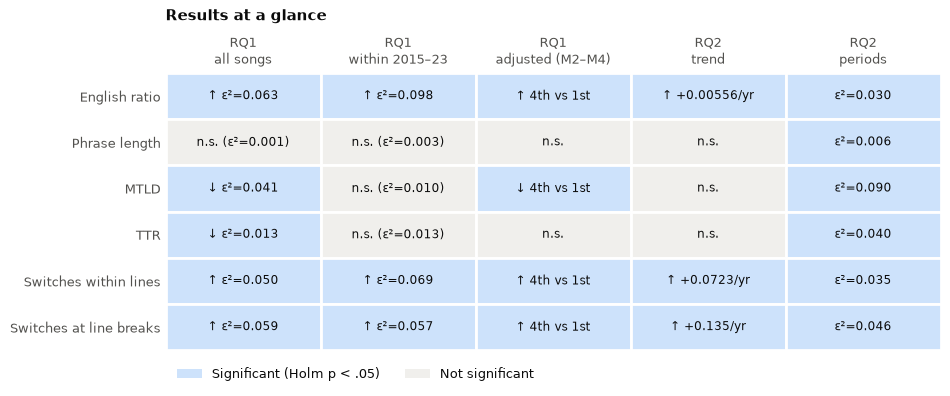

Saved fig01_results_overview.png / .pdf


In [3]:
kw_all = T["rq1_kruskal_all"].set_index("feature")
kw_within = T["rq1_kruskal_within_2015_2023"].set_index("feature")
reg = T["rq1_regression"].set_index("feature")
trend = T["rq2_trend"].set_index("feature")
period_kw = T["rq2_period_kruskal"].set_index("feature")

arrow = lambda x: "↑" if x > 0 else "↓"
cols = ["RQ1\nall songs", "RQ1\nwithin 2015–23", "RQ1\nadjusted (M2–M4)", "RQ2\ntrend", "RQ2\nperiods"]
labels, fills = [], []
for f in MAIN_FEATURES:
    row_l, row_f = [], []
    for sig, txt in [
        (kw_all.loc[f, "p_holm"] < .05, f"{arrow(kw_all.loc[f, 'rho'])} ε²={kw_all.loc[f, 'epsilon2']:.3f}"),
        (kw_within.loc[f, "p_holm"] < .05, f"{arrow(kw_within.loc[f, 'rho'])} ε²={kw_within.loc[f, 'epsilon2']:.3f}"),
        (bool(reg.loc[f, "sig_flexible"]), f"{arrow(reg.loc[f, 'coef_4th_year_fe'])} 4th vs 1st"),
        (trend.loc[f, "trend"] != "no trend", f"{arrow(trend.loc[f, 'sen_slope_per_year'])} {trend.loc[f, 'sen_slope_per_year']:+.3g}/yr"),
        (period_kw.loc[f, "p_holm"] < .05, f"ε²={period_kw.loc[f, 'epsilon2']:.3f}"),
    ]:
        row_l.append(txt if sig else f"n.s. ({txt.split(' ', 1)[-1]})" if "ε²" in txt else "n.s.")
        row_f.append(SIG_FILL if sig else NS_FILL)
    labels.append(row_l); fills.append(row_f)

fig, ax = plt.subplots(figsize=(10, 3.6))
annotated_grid(ax, np.zeros((len(MAIN_FEATURES), len(cols))), labels, None, None, cols,
               [SHORT[f] for f in MAIN_FEATURES], fills=fills)
ax.xaxis.tick_top()
ax.legend(handles=[Patch(facecolor=SIG_FILL, label="Significant (Holm p < .05)"),
                   Patch(facecolor=NS_FILL, label="Not significant")],
          loc="upper left", bbox_to_anchor=(0, -0.02), ncol=2)
ax.set_title("Results at a glance", pad=38)
save(fig, "fig01_results_overview")

### 2.2 Language Tagging Validation

#### What it shows
Latin-only lyric lines (≥ 3 non-filler tokens) checked with py3langid (`05` 6.3, `language_tagging_validation`). Lines that the model did not call English are split into model errors on ordinary English words, other languages, and romanized Korean. The share of English tokens re-tagged as romanized Korean is printed below (`romanized_by_period`).

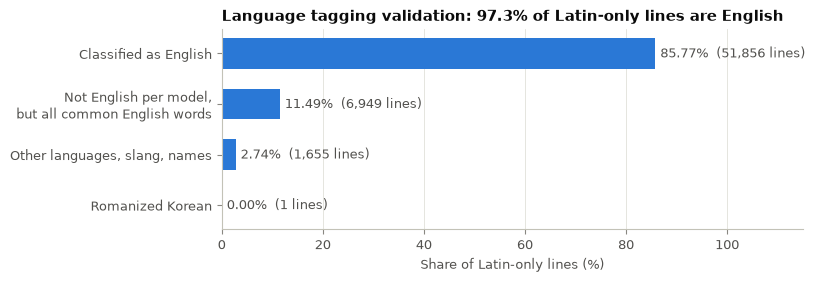

Saved fig02_language_validation.png / .pdf
Romanized Korean tokens re-tagged as Korean:


,songs,en_tokens,romanized,songs_with_romanized,romanized_share_of_en (%)
period,,,,,
2000–04,1042,37952,0,0,0.00
2005–09,2148,87467,1,1,0.00
2010–14,2424,120373,12,1,0.01
2015–19,1529,86229,2,2,0.00
2020–23,728,58419,1,1,0.00
All,7871,390440,16,5,0.00


In [4]:
lid = T["language_tagging_validation"].set_index("type")
order = ["Agree (English)", "All English words", "Other", "Romanized Korean"]
names = {"Agree (English)": "Classified as English", "All English words": "Not English per model,\nbut all common English words",
         "Other": "Other languages, slang, names", "Romanized Korean": "Romanized Korean"}
lid = lid.reindex([o for o in order if o in lid.index])

fig, ax = plt.subplots(figsize=(7.5, 2.6))
y = np.arange(len(lid))
ax.barh(y, lid["share (%)"], color=BLUE, height=0.6)
for yi, (share, n) in enumerate(zip(lid["share (%)"], lid["lines"])):
    ax.text(share + 1, yi, f"{share:.2f}%  ({n:,} lines)", va="center", fontsize=9, color=INK_2)
ax.set_yticks(y, [names[i] for i in lid.index]); ax.invert_yaxis()
ax.set_xlim(0, 115); ax.set_xlabel("Share of Latin-only lines (%)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"Language tagging validation: {lid.loc[['Agree (English)', 'All English words'], 'share (%)'].sum():.1f}% "
             f"of Latin-only lines are English")
save(fig, "fig02_language_validation")

rom = T["romanized_by_period"].set_index("period")
print("Romanized Korean tokens re-tagged as Korean:")
display(rom)

## 3. RQ1: Generational Differences

### 3.1 Medians by Generation

#### What it shows
Median of each feature by generation with bootstrap 95% confidence intervals (`rq1_median_ci`). Panel titles give the Kruskal–Wallis effect size ε² for all RQ1 songs (`rq1_kruskal_all`; `*` Holm p < .05). Wide intervals for the 4th generation reflect its small sample.

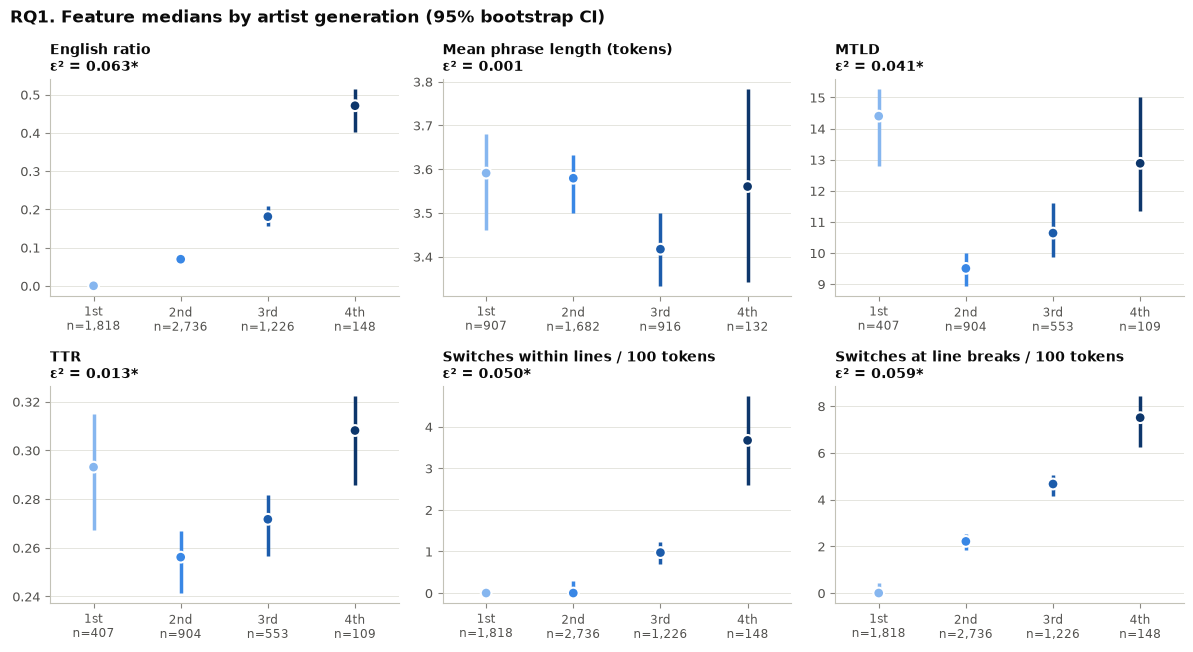

Saved fig03_rq1_medians_by_generation.png / .pdf


In [5]:
ci = T["rq1_median_ci"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6))
for ax, f in zip(axes.flat, MAIN_FEATURES):
    d = ci[ci["feature"] == f].set_index("gen").reindex(GENS)
    x = np.arange(len(GENS))
    ax.vlines(x, d["ci_low"], d["ci_high"], color=[GEN_COLORS[g] for g in GENS], lw=2.5)
    ax.scatter(x, d["median"], s=60, color=[GEN_COLORS[g] for g in GENS], zorder=3,
               edgecolor="white", linewidth=1.5)
    ax.set_xticks(x, [f"{g}\nn={int(n):,}" for g, n in zip(GENS, d["n"])], fontsize=8.5)
    r = kw_all.loc[f]
    ax.set_title(f"{LABELS[f]}\nε² = {r['epsilon2']:.3f}{stars(r['p_holm'])}", fontsize=10)
    ax.set_xlim(-.5, 3.5)
fig.suptitle("RQ1. Feature medians by artist generation (95% bootstrap CI)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "fig03_rq1_medians_by_generation")

### 3.2 Share of Songs with English

#### What it shows
The two-part view of English frequency: the share of songs that contain any English, by generation (`descriptives_by_generation`, `pct_above_0` of `en_ratio`), next to the median English ratio among all songs.

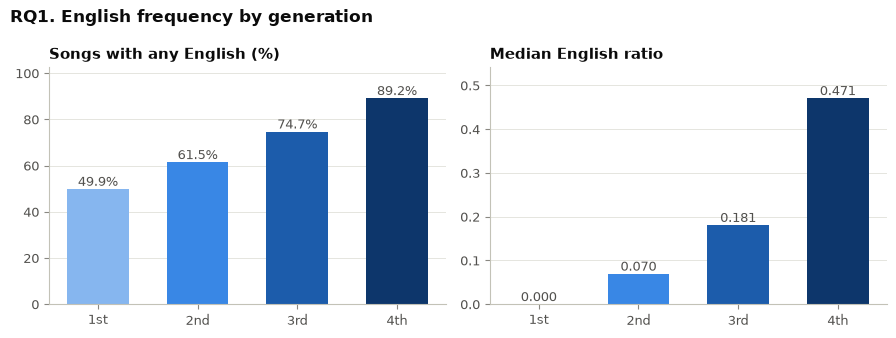

Saved fig04_rq1_english_share.png / .pdf


In [6]:
desc = T["descriptives_by_generation"]
en = desc[desc["feature"] == "en_ratio"].set_index("group").reindex(GENS)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
x = np.arange(len(GENS))
for ax, col, title, fmt in [(axes[0], "pct_above_0", "Songs with any English (%)", "{:.1f}%"),
                            (axes[1], "median", "Median English ratio", "{:.3f}")]:
    vals = en[col].values
    ax.bar(x, vals, color=[GEN_COLORS[g] for g in GENS], width=0.62)
    for xi, v in zip(x, vals):
        ax.text(xi, v, fmt.format(v), ha="center", va="bottom", fontsize=9, color=INK_2)
    ax.set_xticks(x, GENS); ax.set_title(title)
    ax.set_ylim(0, vals.max() * 1.15)
fig.suptitle("RQ1. English frequency by generation", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "fig04_rq1_english_share")

### 3.3 Pairwise Effect Sizes

#### What it shows
Cliff's δ for each pair of generations (later vs. earlier; `rq1_dunn_all`). Blue: the later generation tends to have higher values; red: lower. `*` Dunn's test Holm p < .05. |δ| ≥ .15 small, ≥ .33 medium, ≥ .47 large.

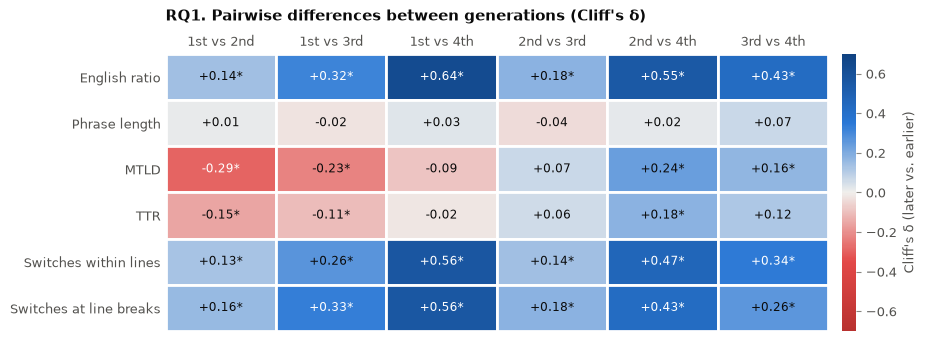

Saved fig05_rq1_pairwise_delta.png / .pdf


In [7]:
dunn = T["rq1_dunn_all"]
pairs = list(dict.fromkeys(dunn["pair"]))
val = dunn.pivot(index="feature", columns="pair", values="cliffs_delta").reindex(index=MAIN_FEATURES, columns=pairs)
pv = dunn.pivot(index="feature", columns="pair", values="p_holm").reindex(index=MAIN_FEATURES, columns=pairs)
lim = np.ceil(np.nanmax(np.abs(val.values)) * 10) / 10
norm = mcolors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
labels = [[f"{v:+.2f}{stars(p)}" for v, p in zip(val.loc[f], pv.loc[f])] for f in MAIN_FEATURES]

fig, ax = plt.subplots(figsize=(9, 3.6))
annotated_grid(ax, val.values, labels, DIV, norm, pairs, [SHORT[f] for f in MAIN_FEATURES])
ax.xaxis.tick_top()
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=DIV), ax=ax, fraction=0.03, pad=0.02)
cb.set_label("Cliff's δ (later vs. earlier)", color=INK_2); cb.outline.set_visible(False)
ax.set_title("RQ1. Pairwise differences between generations (Cliff's δ)", pad=24)
save(fig, "fig05_rq1_pairwise_delta")

### 3.4 Controlling for Release Period: Kruskal–Wallis

#### What it shows
Generational effect size ε² for all RQ1 songs vs. songs released in 2015–2023, when all four generations were active (`rq1_kruskal_all`, `rq1_kruskal_within_2015_2023`). Filled markers: significant (Holm p < .05); hollow: not significant. A difference that stays similar in both is not just a time effect.

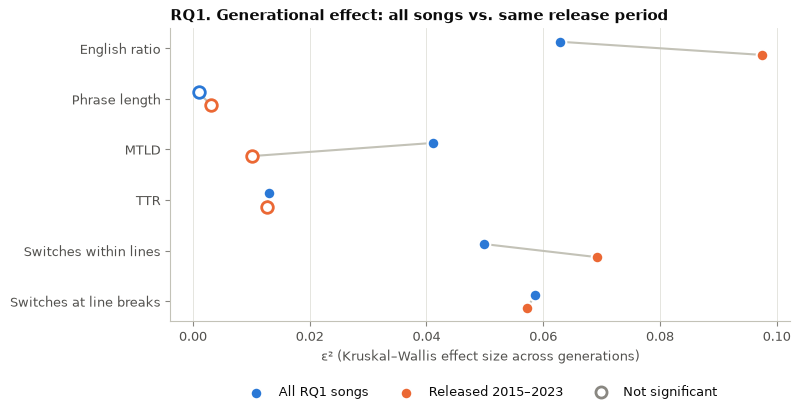

Saved fig06_rq1_within_period.png / .pdf


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(MAIN_FEATURES))
OFF = 0.13
for f_i, f in enumerate(MAIN_FEATURES):
    a, w = kw_all.loc[f], kw_within.loc[f]
    ax.plot([a["epsilon2"], w["epsilon2"]], [f_i - OFF, f_i + OFF], color=AXIS, lw=1.5, zorder=1)
for tbl, color, offset, name in [(kw_all, BLUE, -OFF, "All RQ1 songs"), (kw_within, ORANGE, OFF, "Released 2015–2023")]:
    v = tbl.reindex(MAIN_FEATURES)
    sig = (v["p_holm"] < .05).values
    yy = y + offset
    ax.scatter(v["epsilon2"].values[sig], yy[sig], s=70, color=color, zorder=3, label=name, edgecolor="white", lw=1.5)
    ax.scatter(v["epsilon2"].values[~sig], yy[~sig], s=70, facecolor="white", edgecolor=color, lw=2, zorder=3)
    if not sig.any():
        ax.scatter([], [], s=70, color=color, label=name)
ax.set_yticks(y, [SHORT[f] for f in MAIN_FEATURES]); ax.invert_yaxis()
ax.set_xlabel("ε² (Kruskal–Wallis effect size across generations)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
handles, _ = ax.get_legend_handles_labels()
handles += [Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=MUTED, markersize=8,
                   markeredgewidth=2, label="Not significant")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
ax.set_title("RQ1. Generational effect: all songs vs. same release period")
save(fig, "fig06_rq1_within_period")

### 3.5 Controlling for Release Period: Regression

#### What it shows
4th-generation coefficient (vs. 1st) under five time controls (`rq1_regression_time_controls`): M0 none, M1 linear year, M2 quadratic year, M3 period dummies, M4 year dummies. Filled markers: the joint generation effect is significant in that model (Holm p < .05); hollow: not significant. A coefficient that keeps its sign and size from M0 to M4 is not explained by release time.

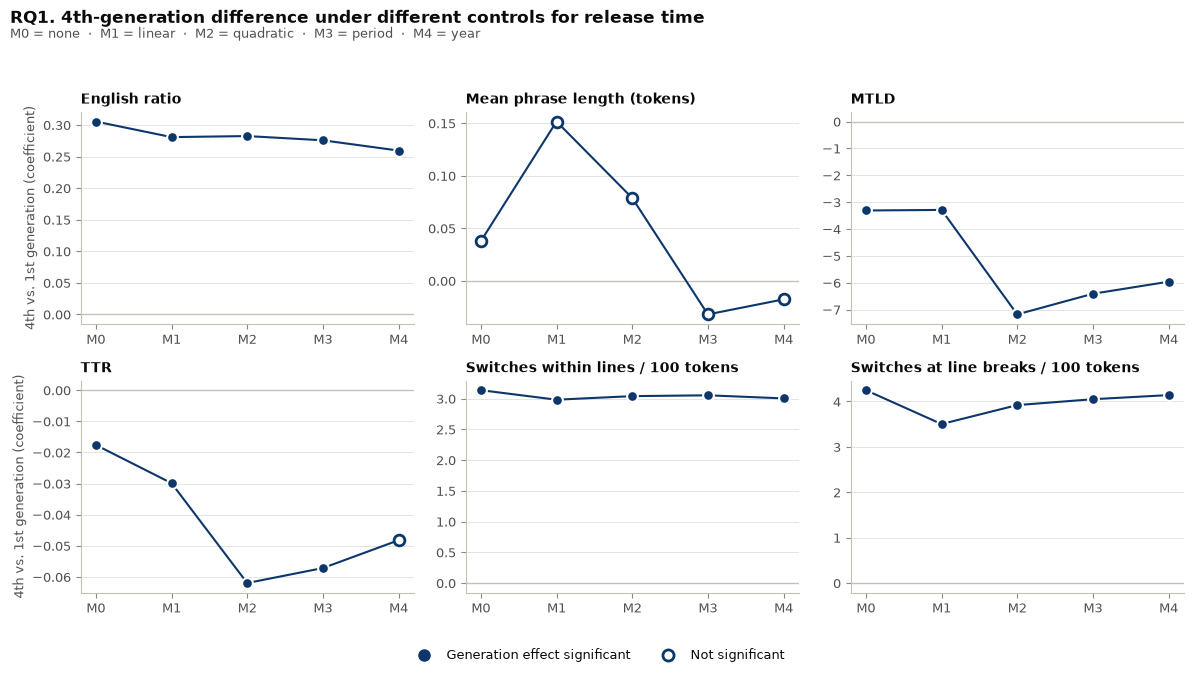

Saved fig07_rq1_regression_time_controls.png / .pdf


In [9]:
tc = T["rq1_regression_time_controls"]
models = list(dict.fromkeys(tc["model"]))
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, f in zip(axes.flat, MAIN_FEATURES):
    d = tc[tc["feature"] == f].set_index("model").reindex(models)
    x = np.arange(len(models))
    sig = (d["p_gen_joint_holm"] < .05).values
    ax.axhline(0, color=AXIS, lw=1)
    ax.plot(x, d["coef_4th"], color=GEN_COLORS["4th"], lw=1.5, zorder=2)
    ax.scatter(x[sig], d["coef_4th"].values[sig], s=60, color=GEN_COLORS["4th"], zorder=3, edgecolor="white", lw=1.5)
    ax.scatter(x[~sig], d["coef_4th"].values[~sig], s=60, facecolor="white", edgecolor=GEN_COLORS["4th"], lw=2, zorder=3)
    ax.set_xticks(x, [m.split()[0] for m in models])
    ax.set_title(LABELS[f], fontsize=10)
axes[0, 0].set_ylabel("4th vs. 1st generation (coefficient)")
axes[1, 0].set_ylabel("4th vs. 1st generation (coefficient)")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=GEN_COLORS["4th"], markersize=8, label="Generation effect significant"),
                    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=GEN_COLORS["4th"],
                           markeredgewidth=2, markersize=8, label="Not significant")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("RQ1. 4th-generation difference under different controls for release time", x=0.01, y=1.03,
             ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.985, "  ·  ".join(f"{m.split()[0]} = {' '.join(m.split()[1:])}" for m in models),
         ha="left", fontsize=9.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
save(fig, "fig07_rq1_regression_time_controls")

### 3.6 Robustness

#### What it shows
ε² of the generational Kruskal–Wallis test under each robustness condition (`robustness_rq1`). `*` Holm p < .05; `≠` direction differs from the baseline; `—` condition not applicable to the feature. Darker cells are larger effects.

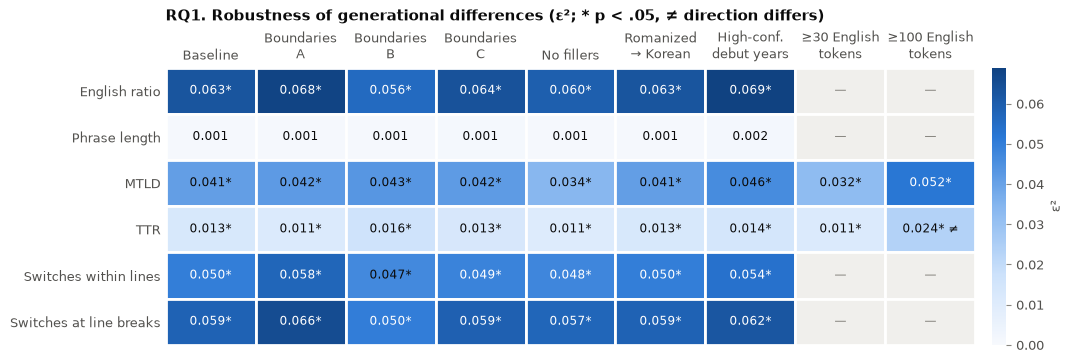

Saved fig08_rq1_robustness.png / .pdf


In [10]:
rob1 = T["robustness_rq1"]
conds = list(dict.fromkeys(rob1["condition"]))
eps = rob1.pivot(index="feature", columns="condition", values="epsilon2").reindex(index=MAIN_FEATURES, columns=conds)
p = rob1.pivot(index="feature", columns="condition", values="p_holm").reindex(index=MAIN_FEATURES, columns=conds)
same = rob1.pivot(index="feature", columns="condition", values="same_direction").reindex(index=MAIN_FEATURES, columns=conds)
labels = [["—" if pd.isna(eps.loc[f, c]) else
           f"{eps.loc[f, c]:.3f}{stars(p.loc[f, c])}{'' if same.loc[f, c] in (True, 'True') else ' ≠'}"
           for c in conds] for f in MAIN_FEATURES]
norm = mcolors.Normalize(vmin=0, vmax=np.nanmax(eps.values))

fig, ax = plt.subplots(figsize=(11, 3.6))
annotated_grid(ax, eps.values, labels, SEQ, norm, [COND_LABELS.get(c, c) for c in conds], [SHORT[f] for f in MAIN_FEATURES])
ax.xaxis.tick_top()
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=SEQ), ax=ax, fraction=0.03, pad=0.02)
cb.set_label("ε²", color=INK_2); cb.outline.set_visible(False)
ax.set_title("RQ1. Robustness of generational differences (ε²; * p < .05, ≠ direction differs)", pad=34)
save(fig, "fig08_rq1_robustness")

## 4. RQ2: Temporal Trends

### 4.1 Yearly Means and Trend

#### What it shows
Yearly mean of each feature, 2000–2023 (`rq2_yearly_mean`). Where the Mann–Kendall test is significant (`rq2_trend`, Holm p < .05), the Sen's slope line is drawn; its intercept is the median of (mean − slope × year). Means are used because the yearly median is 0 in many years for English frequency and code-switching.

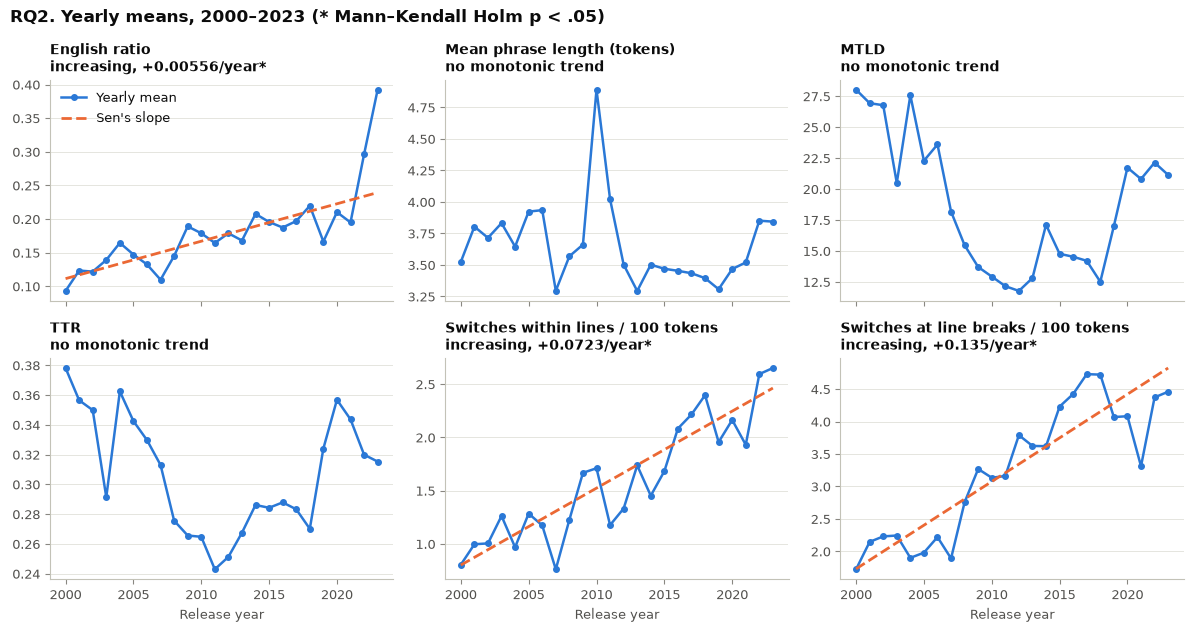

Saved fig09_rq2_yearly_trends.png / .pdf


In [11]:
yearly = T["rq2_yearly_mean"].set_index("release_year")
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True)
for ax, f in zip(axes.flat, MAIN_FEATURES):
    s = yearly[f].dropna()
    ax.plot(s.index, s.values, color=BLUE, marker="o", markersize=4, lw=1.8, label="Yearly mean")
    r = trend.loc[f]
    if r["trend"] != "no trend":
        slope = r["sen_slope_per_year"]
        intercept = np.median(s.values - slope * s.index.values)
        ax.plot(s.index, intercept + slope * s.index.values, color=ORANGE, lw=2, ls="--", label="Sen's slope")
        sub = f"{r['trend']}, {slope:+.3g}/year*"
    else:
        sub = "no monotonic trend"
    ax.set_title(f"{LABELS[f]}\n{sub}", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Release year")
axes[0, 0].legend(loc="upper left")
fig.suptitle("RQ2. Yearly means, 2000–2023 (* Mann–Kendall Holm p < .05)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "fig09_rq2_yearly_trends")

### 4.2 Period Medians

#### What it shows
Median of each feature by five-year release period for all RQ2 songs and for Korean artists only (`rq2_period_kruskal`, `rq2_period_kruskal_korean`). Panel titles give ε² for all songs (`*` Holm p < .05). This view shows non-monotonic change, such as the U-shape in lexical diversity, which the trend test in 4.1 cannot detect.

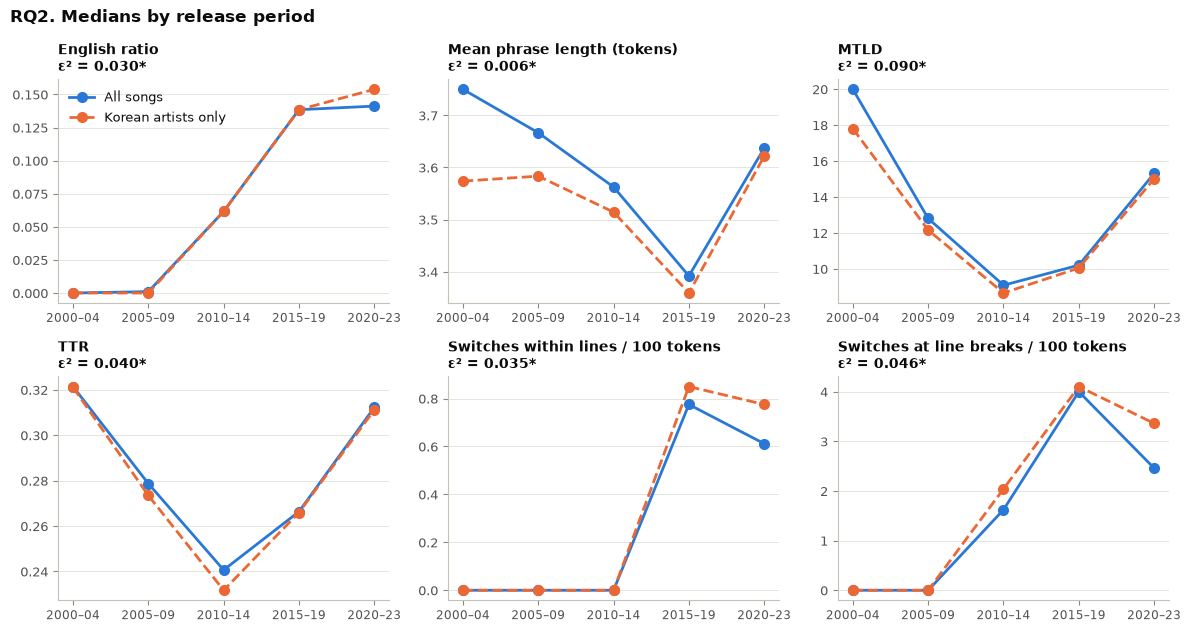

Saved fig10_rq2_period_medians.png / .pdf


In [12]:
pk_kr = T["rq2_period_kruskal_korean"].set_index("feature")
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
x = np.arange(len(PERIODS))
for ax, f in zip(axes.flat, MAIN_FEATURES):
    for tbl, color, name, ls in [(period_kw, BLUE, "All songs", "-"), (pk_kr, ORANGE, "Korean artists only", "--")]:
        ax.plot(x, [tbl.loc[f, f"median_{p}"] for p in PERIODS], color=color, marker="o", lw=2, ls=ls, label=name)
    ax.set_xticks(x, PERIODS, fontsize=8.5)
    r = period_kw.loc[f]
    ax.set_title(f"{LABELS[f]}\nε² = {r['epsilon2']:.3f}{stars(r['p_holm'])}", fontsize=10)
axes[0, 0].legend(loc="upper left")
fig.suptitle("RQ2. Medians by release period", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "fig10_rq2_period_medians")

### 4.3 Period Effect Sizes

#### What it shows
Cliff's δ between release periods (later vs. earlier; `rq2_period_pairs`): the four adjacent pairs, plus the fall (2000–04 → 2010–14) and the rise (2010–14 → 2020–23). Blue: later period higher; red: lower; `*` Holm p < .05.

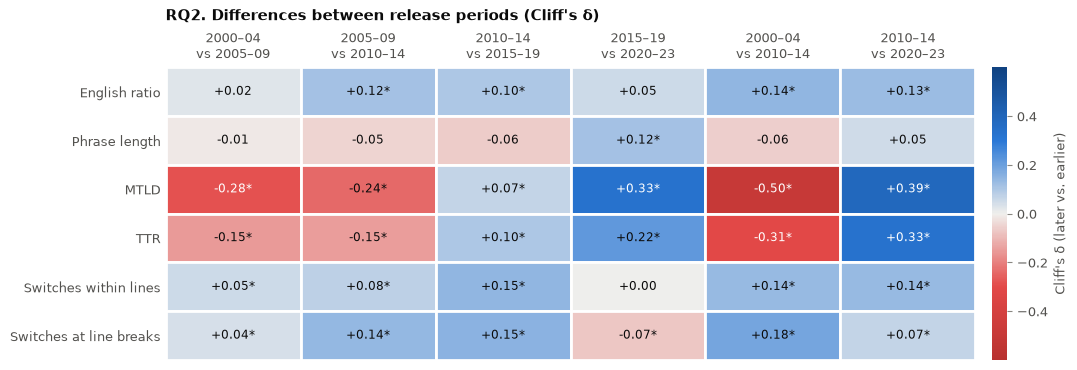

Saved fig11_rq2_period_delta.png / .pdf


In [13]:
pp = T["rq2_period_pairs"]
pairs = list(dict.fromkeys(pp["pair"]))
val = pp.pivot(index="feature", columns="pair", values="cliffs_delta").reindex(index=MAIN_FEATURES, columns=pairs)
pv = pp.pivot(index="feature", columns="pair", values="p_holm").reindex(index=MAIN_FEATURES, columns=pairs)
lim = np.ceil(np.nanmax(np.abs(val.values)) * 10) / 10
norm = mcolors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
labels = [[f"{v:+.2f}{stars(q)}" for v, q in zip(val.loc[f], pv.loc[f])] for f in MAIN_FEATURES]

fig, ax = plt.subplots(figsize=(11, 3.8))
annotated_grid(ax, val.values, labels, DIV, norm, [p_.replace(" vs ", "\nvs ") for p_ in pairs],
               [SHORT[f] for f in MAIN_FEATURES])
ax.xaxis.tick_top()
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=DIV), ax=ax, fraction=0.03, pad=0.02)
cb.set_label("Cliff's δ (later vs. earlier)", color=INK_2); cb.outline.set_visible(False)
ax.set_title("RQ2. Differences between release periods (Cliff's δ)", pad=34)
save(fig, "fig11_rq2_period_delta")

### 4.4 Components of the Change in Lexical Diversity

#### What it shows
- **Top:** period medians of the repetition and part-of-speech measures for songs with 50+ English tokens (`rq2_lexdiv_components`). Panel titles give ε² (`*` Holm p < .05).
- **Bottom:** Cliff's δ for the fall (2010–14 vs. 2000–04) and the rise (2020–23 vs. 2010–14) of each measure. A measure that moves in opposite directions in the two phases mirrors the U-shape in MTLD.

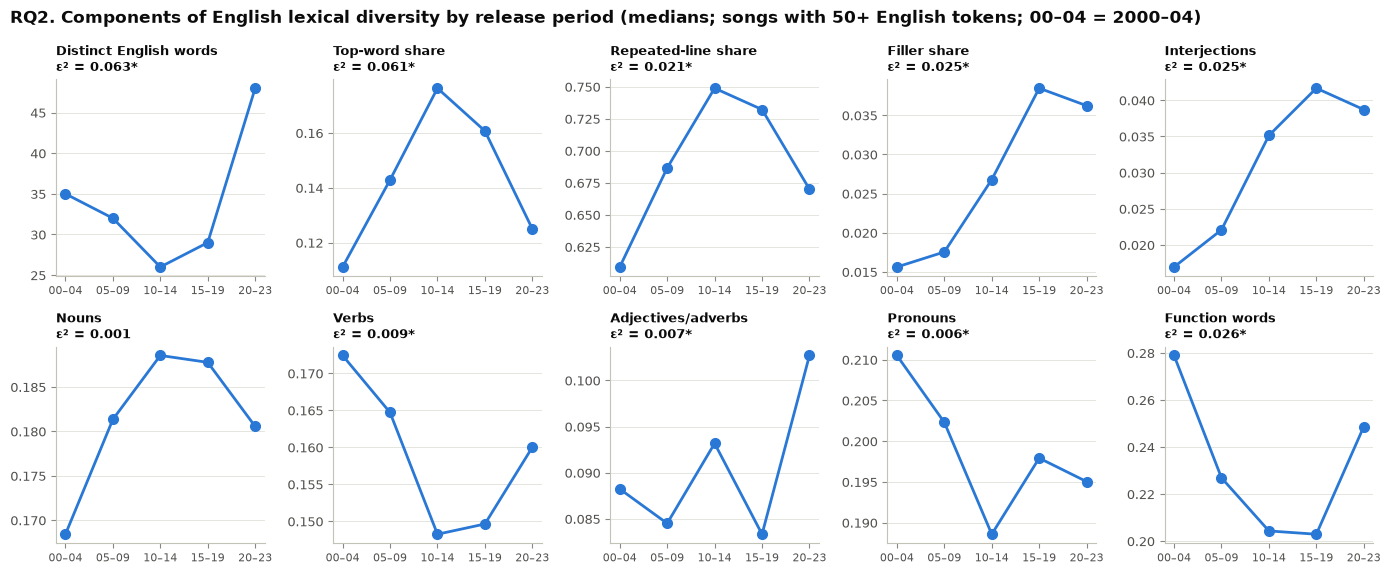

Saved fig12_rq2_lexdiv_components.png / .pdf


In [14]:
comp = T["rq2_lexdiv_components"].set_index("measure")
measures = list(comp.index)
n_c = 5
n_r = int(np.ceil(len(measures) / n_c))
fig, axes = plt.subplots(n_r, n_c, figsize=(14, 2.9 * n_r))
x = np.arange(len(PERIODS))
for ax, m in zip(axes.flat, measures):
    vals = [comp.loc[m, f"median_{p}"] for p in PERIODS]
    ax.plot(x, vals, color=BLUE, marker="o", lw=2)
    ax.set_xticks(x, [p[2:] for p in PERIODS], fontsize=8)
    ax.set_title(f"{comp.loc[m, 'label']}\nε² = {comp.loc[m, 'epsilon2']:.3f}{stars(comp.loc[m, 'p_holm'])}", fontsize=9.5)
for ax in list(axes.flat)[len(measures):]:
    ax.set_visible(False)
fig.suptitle("RQ2. Components of English lexical diversity by release period (medians; songs with 50+ English tokens; 00–04 = 2000–04)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "fig12_rq2_lexdiv_components")

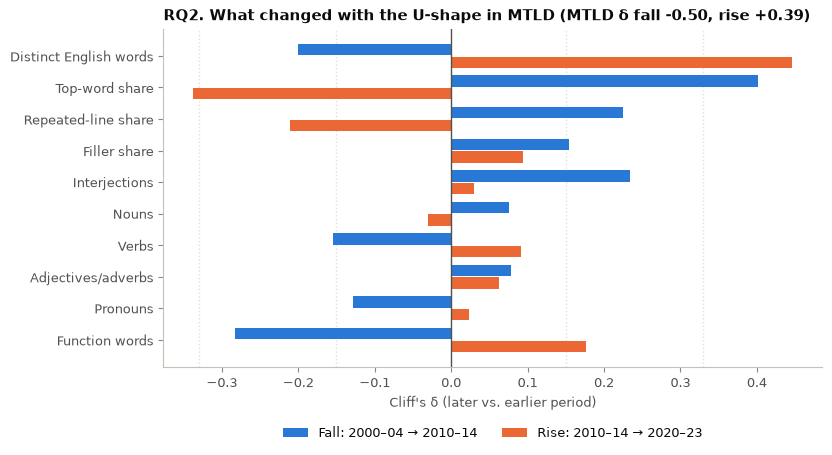

Saved fig13_rq2_lexdiv_fall_rise.png / .pdf


In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
y = np.arange(len(measures))
h = 0.36
ax.barh(y - h / 2 - 0.02, comp["delta_fall"], height=h, color=BLUE, label="Fall: 2000–04 → 2010–14")
ax.barh(y + h / 2 + 0.02, comp["delta_rise"], height=h, color=ORANGE, label="Rise: 2010–14 → 2020–23")
ax.axvline(0, color=INK_2, lw=1)
for thr in (-.33, -.15, .15, .33):
    ax.axvline(thr, color=GRID, lw=1, ls=":", zorder=0)
ax.set_yticks(y, comp["label"]); ax.invert_yaxis()
ax.set_xlabel("Cliff's δ (later vs. earlier period)")
ax.grid(axis="x", visible=False); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
mt = T["rq2_period_pairs"].set_index(["feature", "pair"])["cliffs_delta"]
ax.set_title(f"RQ2. What changed with the U-shape in MTLD "
             f"(MTLD δ fall {mt.get(('mtld', '2000–04 vs 2010–14'), np.nan):+.2f}, "
             f"rise {mt.get(('mtld', '2010–14 vs 2020–23'), np.nan):+.2f})")
save(fig, "fig13_rq2_lexdiv_fall_rise")

### 4.5 Most Frequent English Words

#### What it shows
Top 15 English words per period in songs with 50+ English tokens, with their share of all English tokens (`rq2_top_english_words`; `*` filler). Shown as a table for the report.

In [16]:
top = T["rq2_top_english_words"].rename(columns={"Unnamed: 0": "rank"}).set_index("rank")
display(top)

,2000–04,2005–09,2010–14,2015–19,2020–23
rank,,,,,
1,you (4.5%),you (4.6%),you (4.7%),you (4.4%),you (4.0%)
2,i (3.8%),i (4.3%),i (3.8%),i (3.7%),i (3.8%)
3,me (2.7%),me (2.4%),oh* (3.3%),me (2.9%),me (2.6%)
4,the (2.6%),the (2.2%),me (2.2%),oh* (2.1%),the (1.8%)
5,my (2.2%),love (2.0%),love (2.1%),it (1.7%),my (1.8%)
6,to (1.7%),my (1.8%),my (1.8%),my (1.7%),it (1.7%)
7,it (1.6%),oh* (1.8%),baby (1.7%),love (1.7%),i'm (1.5%)
8,love (1.3%),it (1.6%),it (1.7%),baby (1.5%),oh* (1.5%)
9,and (1.2%),to (1.5%),the (1.4%),yeah* (1.4%),yeah* (1.4%)


### 4.6 Robustness

#### What it shows
Sen's slope per year under each RQ2 robustness condition (`robustness_rq2`). Blue: significant increase; red: significant decrease; gray: no significant trend (Holm p < .05). `≠` direction differs from the baseline; `—` not applicable.

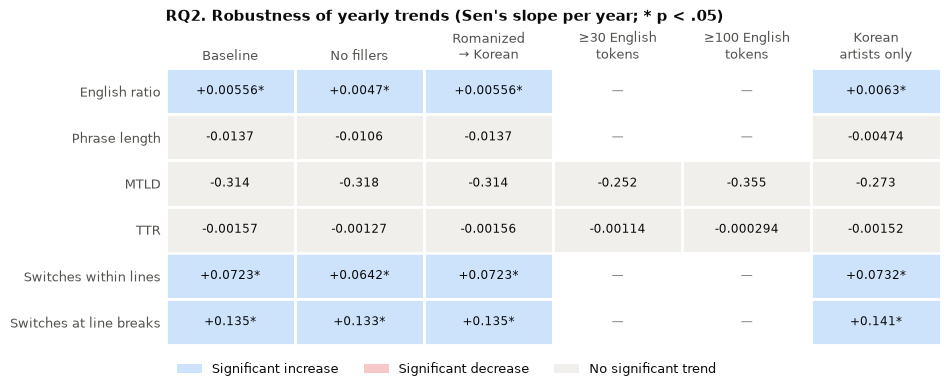

Saved fig14_rq2_robustness.png / .pdf


In [17]:
rob2 = T["robustness_rq2"]
conds = list(dict.fromkeys(rob2["condition"]))
slope = rob2.pivot(index="feature", columns="condition", values="sen_slope_per_year").reindex(index=MAIN_FEATURES, columns=conds)
p = rob2.pivot(index="feature", columns="condition", values="p_holm").reindex(index=MAIN_FEATURES, columns=conds)
same = rob2.pivot(index="feature", columns="condition", values="same_direction").reindex(index=MAIN_FEATURES, columns=conds)
labels, fills = [], []
for f in MAIN_FEATURES:
    rl, rf = [], []
    for c in conds:
        s, q = slope.loc[f, c], p.loc[f, c]
        if pd.isna(s):
            rl.append("—"); rf.append("white"); continue
        rl.append(f"{s:+.3g}{stars(q)}{'' if same.loc[f, c] in (True, 'True') else ' ≠'}")
        rf.append(("#cde2fb" if s > 0 else "#f6c9c8") if q < .05 else NEUTRAL)
    labels.append(rl); fills.append(rf)

fig, ax = plt.subplots(figsize=(10, 3.6))
annotated_grid(ax, slope.values, labels, None, None, [COND_LABELS.get(c, c) for c in conds], [SHORT[f] for f in MAIN_FEATURES], fills=fills)
ax.xaxis.tick_top()
ax.legend(handles=[Patch(facecolor="#cde2fb", label="Significant increase"),
                   Patch(facecolor="#f6c9c8", label="Significant decrease"),
                   Patch(facecolor=NEUTRAL, label="No significant trend")],
          loc="upper left", bbox_to_anchor=(0, -0.02), ncol=3)
ax.set_title("RQ2. Robustness of yearly trends (Sen's slope per year; * p < .05)", pad=34)
save(fig, "fig14_rq2_robustness")

## 5. Figure List

In [18]:
figs = sorted(FIG_DIR.glob("fig*.png"))
print(f"{len(figs)} figures in {FIG_DIR}:")
for f in figs:
    print(" ", f.name)

14 figures in ../results/figures:
  fig01_results_overview.png
  fig02_language_validation.png
  fig03_rq1_medians_by_generation.png
  fig04_rq1_english_share.png
  fig05_rq1_pairwise_delta.png
  fig06_rq1_within_period.png
  fig07_rq1_regression_time_controls.png
  fig08_rq1_robustness.png
  fig09_rq2_yearly_trends.png
  fig10_rq2_period_medians.png
  fig11_rq2_period_delta.png
  fig12_rq2_lexdiv_components.png
  fig13_rq2_lexdiv_fall_rise.png
  fig14_rq2_robustness.png
